Notebook criado para visualização da geração de imagens:

Imports:

In [1]:
import os
import math
from PIL import Image
import matplotlib.pyplot as plt

#### Funções:

In [6]:
def plot_images(folder, title, cols=4):

    image_files = sorted([
        f for f in os.listdir(folder)
        if f.endswith(".png")
    ])

    if len(image_files) == 0:
        print(f"Nenhuma imagem encontrada em {folder}")
        return

    rows = math.ceil(len(image_files) / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(3 * cols, 3 * rows),
        squeeze=False
    )

    axes = axes.flatten()

    if rows == 1:
        axes = [axes]

    axes = [ax for row in axes for ax in (row if isinstance(row, (list, tuple)) else [row])]

    for ax in axes:
        ax.axis("off")

    for ax, filename in zip(axes, image_files):

        image = Image.open(
            os.path.join(folder, filename)
        )

        ax.imshow(image, cmap="gray")
        ax.set_title(filename, fontsize=8)
        ax.axis("off")

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()


# Mnist dataset

In [3]:
samples_dir = "./samples/mnist"
steps_dir = os.path.join(samples_dir, "denoising_steps")

Imagens geradas:

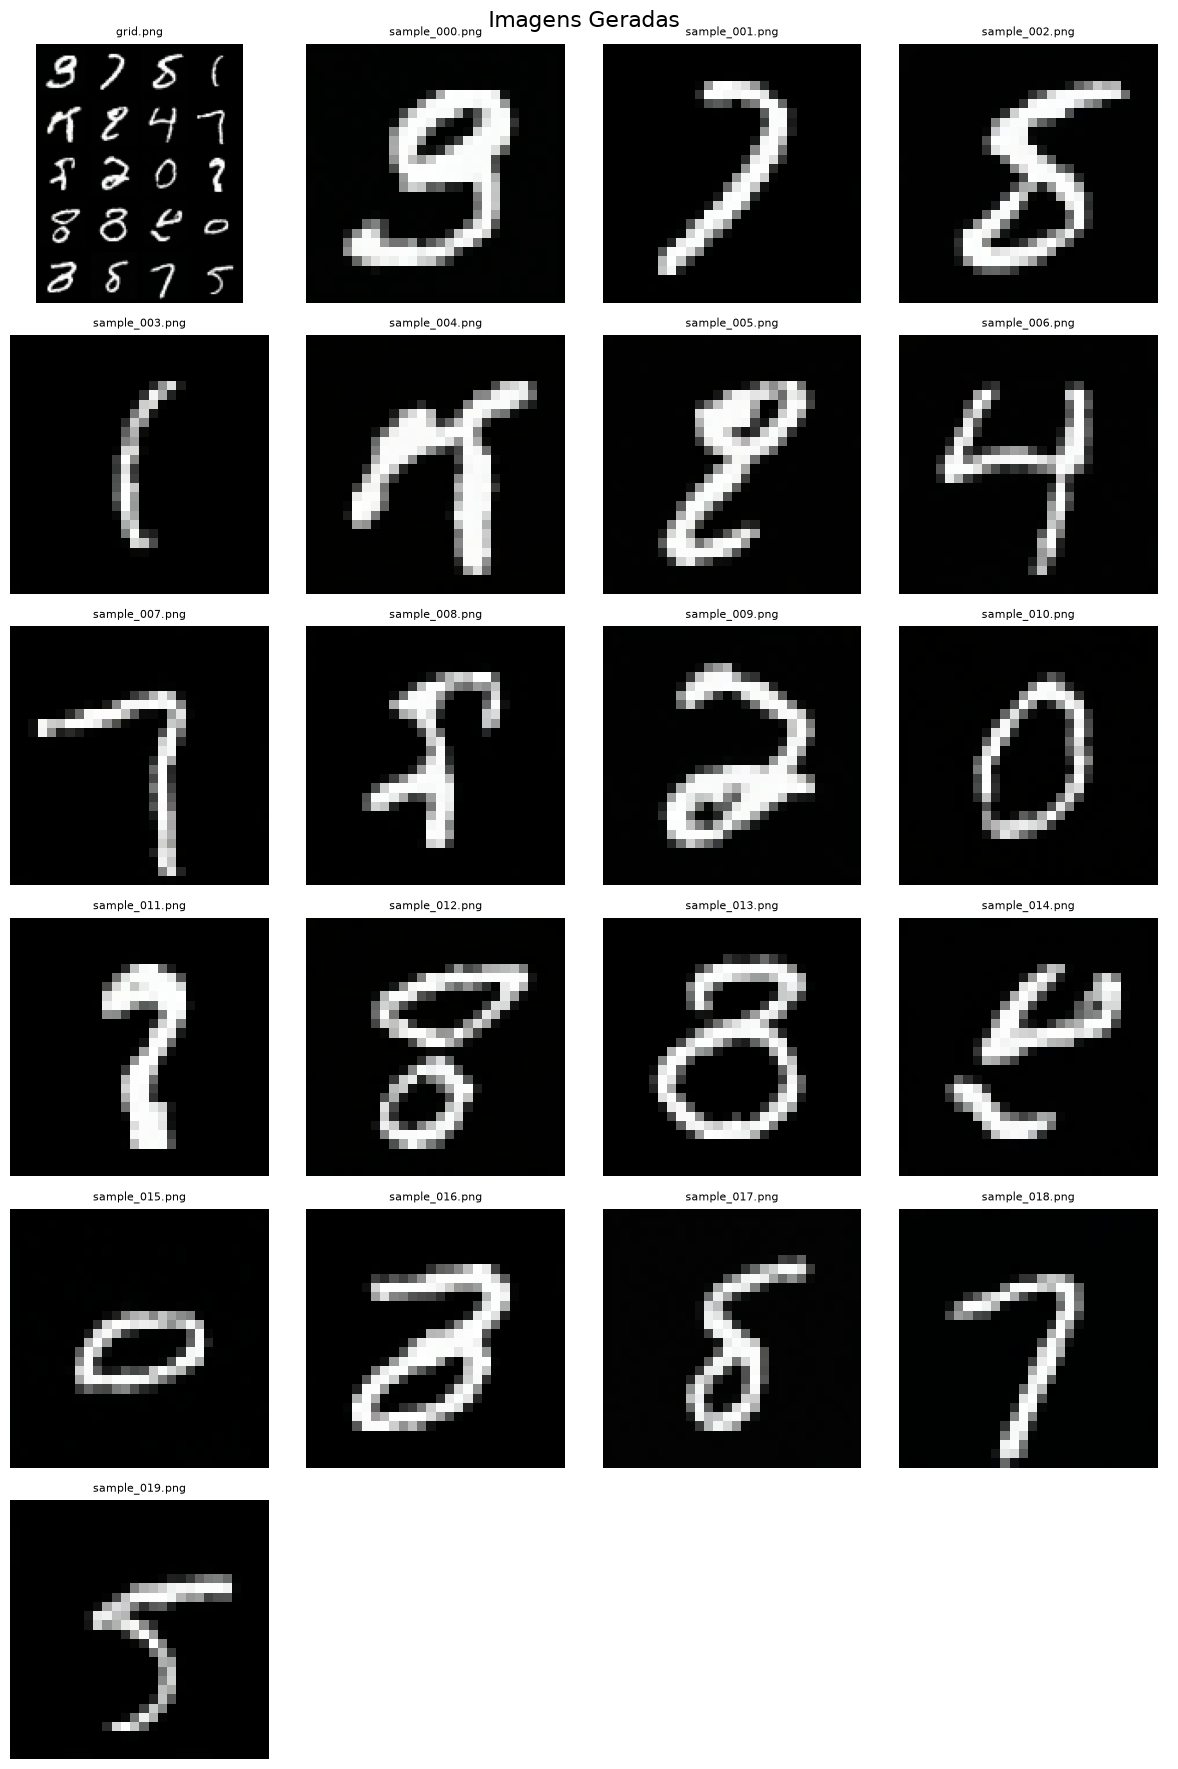

In [7]:
plot_images(
    samples_dir,
    "Imagens Geradas",
    cols=4
)

Observando denoising:

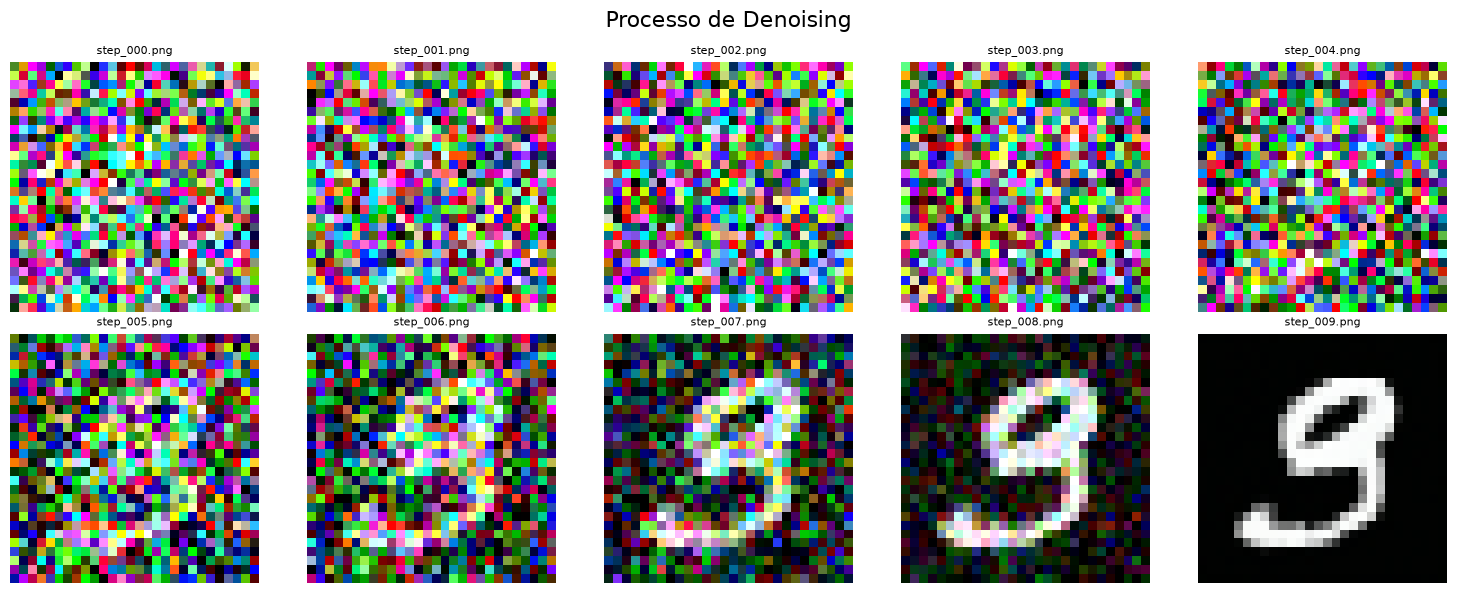

In [8]:
if os.path.exists(steps_dir):

    plot_images(
        steps_dir,
        "Processo de Denoising",
        cols=5
    )

else:

    print("Pasta denoising_steps não encontrada.")